In [2]:
import pandas as pd
print("pandas version:", pd.__version__)

pandas version: 3.1.1


In [5]:
import pandas as pd

orders = pd.read_csv("../data/olist_orders_dataset.csv")

print(orders.shape)
print(orders.columns.tolist())
orders.head()

(99441, 8)
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
import os
print("Current folder:", os.getcwd())
print("Files in ../data:", os.listdir("../data"))

Current folder: c:\Users\ankit\ecommerce-analytics\notebooks
Files in ../data: []


In [6]:
orders.info()
print(orders.isnull().sum())
print(orders["order_status"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_deliv

In [7]:
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

orders.dtypes

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [8]:
orders["delivery_days"] = (
    orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]
).dt.days

orders["purchase_month"] = orders["order_purchase_timestamp"].dt.to_period("M")

orders[["order_id", "delivery_days", "purchase_month"]].head()

,order_id,delivery_days,purchase_month
0,e481f51cbdc54678b7cc49136f2d6af7,8.0,2017-10
1,53cdb2fc8bc7dce0b6741e2150273451,13.0,2018-07
2,47770eb9100c2d0c44946d9cf07ec65d,9.0,2018-08
3,949d5b44dbf5de918fe9c16f97b45f8a,13.0,2017-11
4,ad21c59c0840e6cb83a9ceb5573f8159,2.0,2018-02


In [9]:
customers = pd.read_csv("../data/olist_customers_dataset.csv")
items     = pd.read_csv("../data/olist_order_items_dataset.csv")
payments  = pd.read_csv("../data/olist_order_payments_dataset.csv")
products  = pd.read_csv("../data/olist_products_dataset.csv")
reviews   = pd.read_csv("../data/olist_order_reviews_dataset.csv")

for name, df in [("customers", customers), ("items", items), ("payments", payments), ("products", products), ("reviews", reviews)]:
    print(name, df.shape)

customers (99441, 5)
items (112650, 7)
payments (103886, 5)
products (32951, 9)
reviews (99224, 7)


In [10]:
# Revenue per order, from items
order_items = items.groupby("order_id").agg(
    items_count=("order_item_id", "count"),
    price=("price", "sum"),
    freight=("freight_value", "sum"),
).reset_index()

# Payments per order
order_pay = payments.groupby("order_id").agg(
    payment_value=("payment_value", "sum"),
    payment_type=("payment_type", "first"),
).reset_index()

# Review score per order
order_reviews = reviews.groupby("order_id").agg(
    review_score=("review_score", "mean"),
).reset_index()

# Join everything onto orders
master = (
    orders
    .merge(customers, on="customer_id", how="left")
    .merge(order_items, on="order_id", how="left")
    .merge(order_pay, on="order_id", how="left")
    .merge(order_reviews, on="order_id", how="left")
)

print(master.shape)
print("unique orders:", master["order_id"].nunique())
master.head()

(99441, 20)
unique orders: 99441


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,purchase_month,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,items_count,price,freight,payment_value,payment_type,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.0,2017-10,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1.0,29.99,8.72,38.71,credit_card,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.0,2018-07,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1.0,118.70,22.76,141.46,boleto,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.0,2018-08,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1.0,159.90,19.22,179.12,credit_card,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.0,2017-11,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,1.0,45.00,27.20,72.20,credit_card,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.0,2018-02,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,1.0,19.90,8.72,28.62,credit_card,5.0


In [11]:
master.to_csv("../outputs/master.csv", index=False)

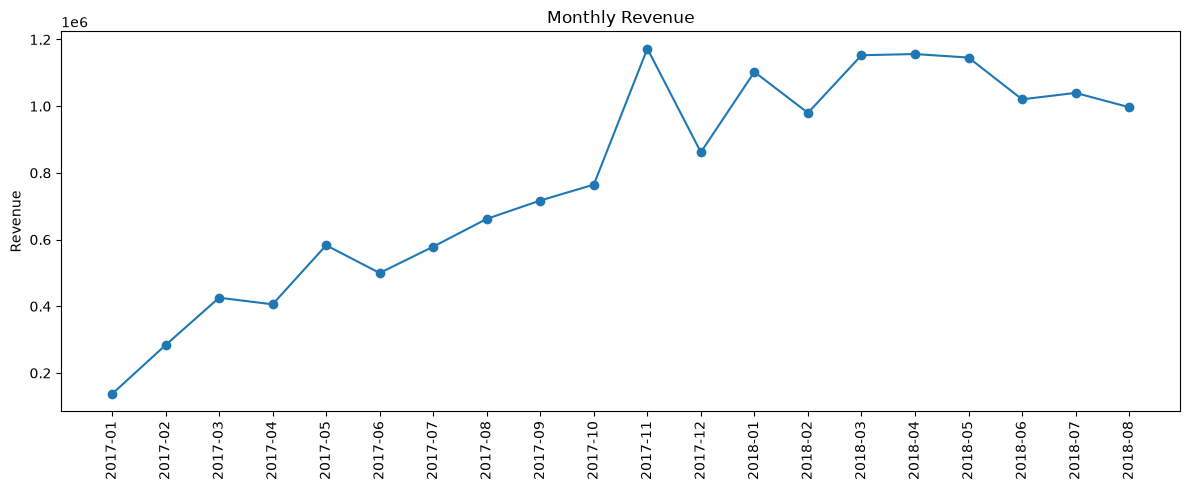

,purchase_month,orders,revenue,avg_order_value
3,2017-01,787,137006.76,174.087370
4,2017-02,1718,283621.94,165.088440
5,2017-03,2617,425656.40,162.650516
6,2017-04,2377,405988.38,170.798645
7,2017-05,3640,582926.16,160.144549
8,2017-06,3205,499827.47,155.952409
9,2017-07,3946,578858.58,146.695028
10,2017-08,4272,662071.77,154.979347
11,2017-09,4227,717195.22,169.670031
12,2017-10,4547,764785.28,168.195575


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sales = master[~master["order_status"].isin(["canceled", "unavailable"])].copy()

monthly = sales.groupby("purchase_month").agg(
    orders=("order_id", "nunique"),
    revenue=("payment_value", "sum"),
).reset_index()
monthly["avg_order_value"] = monthly["revenue"] / monthly["orders"]
monthly["purchase_month"] = monthly["purchase_month"].astype(str)
monthly = monthly[(monthly["purchase_month"] >= "2017-01") & (monthly["purchase_month"] <= "2018-08")]

plt.figure(figsize=(12, 5))
plt.plot(monthly["purchase_month"], monthly["revenue"], marker="o")
plt.xticks(rotation=90)
plt.title("Monthly Revenue")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

monthly

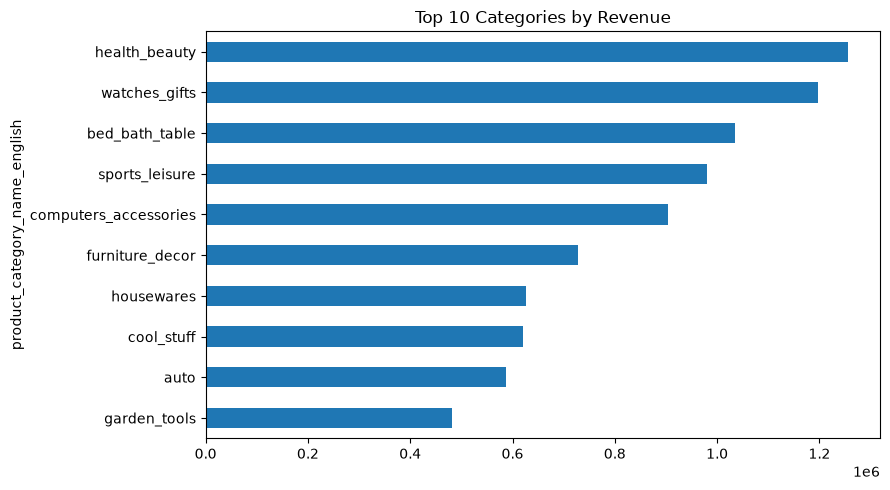

product_category_name_english
health_beauty            1255695.13
watches_gifts            1198185.21
bed_bath_table           1035964.06
sports_leisure            979740.92
computers_accessories     904322.02
furniture_decor           727465.05
housewares                626825.80
cool_stuff                620770.49
auto                      586585.73
garden_tools              481009.94
Name: price, dtype: float64

In [13]:
cat = pd.read_csv("../data/product_category_name_translation.csv")

item_detail = (
    items.merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
         .merge(cat, on="product_category_name", how="left")
)
item_detail = item_detail[item_detail["order_id"].isin(sales["order_id"])]

top_cat = (
    item_detail.groupby("product_category_name_english")["price"]
    .sum().sort_values(ascending=False).head(10)
)

top_cat.sort_values().plot(kind="barh", figsize=(9, 5), title="Top 10 Categories by Revenue")
plt.tight_layout()
plt.show()

top_cat

In [14]:
snapshot = sales["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm = sales.groupby("customer_unique_id").agg(
    recency=("order_purchase_timestamp", lambda x: (snapshot - x.max()).days),
    frequency=("order_id", "nunique"),
    monetary=("payment_value", "sum"),
).reset_index()

print(rfm.shape)
print("Share of repeat customers:", (rfm["frequency"] > 1).mean())
rfm.describe()

(94990, 4)
Share of repeat customers: 0.030403200336877566


,recency,frequency,monetary
count,94990.000000,94990.000000,94990.000000
mean,243.448374,1.033867,165.692568
std,152.999947,0.210826,226.740288
min,1.000000,1.000000,0.000000
25%,119.000000,1.000000,63.100000
50%,224.000000,1.000000,107.900000
75%,352.000000,1.000000,182.940000
max,729.000000,16.000000,13664.080000


In [15]:
import numpy as np

# Recency: recent buyers get a higher score (5 = most recent)
rfm["r_score"] = pd.qcut(rfm["recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)

# Monetary: higher spenders get a higher score (rank first avoids duplicate-edge errors)
rfm["m_score"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Segments (order matters: first matching rule wins)
conditions = [
    (rfm["frequency"] > 1) & (rfm["r_score"] >= 4) & (rfm["m_score"] >= 4),
    (rfm["frequency"] > 1),
    (rfm["frequency"] == 1) & (rfm["r_score"] >= 4) & (rfm["m_score"] >= 4),
    (rfm["frequency"] == 1) & (rfm["r_score"] >= 4),
    (rfm["frequency"] == 1) & (rfm["r_score"] <= 2) & (rfm["m_score"] >= 4),
]
labels = [
    "Champions",
    "Repeat Customers",
    "New High-Value",
    "Recent One-Timers",
    "At-Risk High-Value",
]
rfm["segment"] = np.select(conditions, labels, default="Lost / Low-Value")

summary = rfm.groupby("segment").agg(
    customers=("customer_unique_id", "count"),
    avg_recency=("recency", "mean"),
    avg_spend=("monetary", "mean"),
    total_revenue=("monetary", "sum"),
).round(1)
summary["pct_customers"] = (summary["customers"] / summary["customers"].sum() * 100).round(1)
summary["pct_revenue"] = (summary["total_revenue"] / summary["total_revenue"].sum() * 100).round(1)

summary.sort_values("total_revenue", ascending=False)

,customers,avg_recency,avg_spend,total_revenue,pct_customers,pct_revenue
segment,,,,,,
Lost / Low-Value,41325,323.3,108.0,4464867.2,43.5,28.4
New High-Value,14676,97.0,303.1,4447765.6,15.5,28.3
At-Risk High-Value,13961,400.2,309.3,4317961.9,14.7,27.4
Recent One-Timers,22140,94.9,73.1,1618008.3,23.3,10.3
Repeat Customers,1875,298.2,273.9,513511.6,2.0,3.3
Champions,1013,93.8,372.2,377022.5,1.1,2.4


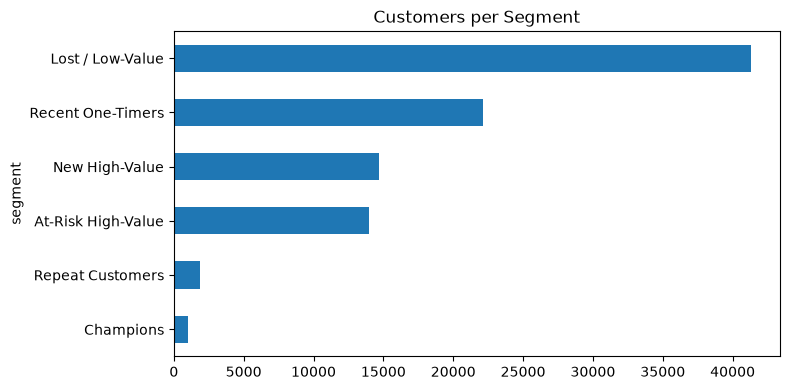

In [16]:
summary["customers"].sort_values().plot(kind="barh", figsize=(8, 4), title="Customers per Segment")
plt.tight_layout()
plt.show()

In [17]:
rfm.to_csv("../outputs/rfm_segments.csv", index=False)

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = rfm[["recency", "frequency", "monetary"]].copy()
X["frequency"] = np.log1p(X["frequency"])   # reduce skew
X["monetary"] = np.log1p(X["monetary"])     # reduce skew
X_scaled = StandardScaler().fit_transform(X)

sample_idx = np.random.RandomState(42).choice(len(X_scaled), 10000, replace=False)

results = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    sil = silhouette_score(X_scaled[sample_idx], km.labels_[sample_idx])
    results.append((k, round(km.inertia_), round(sil, 3)))

pd.DataFrame(results, columns=["k", "inertia", "silhouette"])

,k,inertia,silhouette
0,2,193512,0.704
1,3,128535,0.357
2,4,87346,0.368
3,5,71654,0.351
4,6,60414,0.346
5,7,51686,0.360


In [19]:
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X_scaled)
rfm["cluster"] = km.labels_

profile = rfm.groupby("cluster").agg(
    customers=("customer_unique_id", "count"),
    avg_recency=("recency", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_spend=("monetary", "mean"),
    total_revenue=("monetary", "sum"),
).round(1)
profile["pct_customers"] = (profile["customers"] / profile["customers"].sum() * 100).round(1)
profile["pct_revenue"] = (profile["total_revenue"] / profile["total_revenue"].sum() * 100).round(1)
profile

,customers,avg_recency,avg_frequency,avg_spend,total_revenue,pct_customers,pct_revenue
cluster,,,,,,,
0,36350,152.5,1.0,69.4,2521557.1,38.3,16.0
1,28374,180.0,1.0,319.3,9060511.1,29.9,57.6
2,2888,226.5,2.1,308.4,890534.1,3.0,5.7
3,27378,431.7,1.0,119.3,3266534.6,28.8,20.8


In [20]:
pd.crosstab(rfm["segment"], rfm["cluster"])

cluster,0,1,2,3
segment,,,,
At-Risk High-Value,0,5751,0,8210
Champions,0,0,1013,0
Lost / Low-Value,14387,7770,0,19168
New High-Value,129,14547,0,0
Recent One-Timers,21834,306,0,0
Repeat Customers,0,0,1875,0


In [21]:
rfm.to_csv("../outputs/rfm_clusters.csv", index=False)

In [23]:
delivered = master[master["order_status"] == "delivered"].dropna(
    subset=["order_delivered_customer_date"]
).copy()

delivered["late"] = (
    delivered["order_delivered_customer_date"] > delivered["order_estimated_delivery_date"]
)

print("Late deliveries (%):", round(delivered["late"].mean() * 100, 1))
print(delivered["delivery_days"].describe())
print(delivered.groupby("late")["review_score"].mean())

# Slowest and fastest states
state_days = delivered.groupby("customer_state")["delivery_days"].agg(["mean", "count"])
state_days[state_days["count"] > 100].sort_values("mean").round(1)

Late deliveries (%): 8.1
count    96470.000000
mean        12.093604
std          9.551380
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: delivery_days, dtype: float64
late
False    4.294292
True     2.566506
Name: review_score, dtype: float64


,mean,count
customer_state,,
SP,8.3,40494
PR,11.5,4923
MG,11.5,11354
DF,12.5,2080
SC,14.5,3546
RS,14.8,5344
RJ,14.8,12350
GO,15.2,1957
MS,15.2,701


In [24]:
first = (
    delivered.sort_values("order_purchase_timestamp")
    .groupby("customer_unique_id").first().reset_index()[["customer_unique_id", "late", "review_score"]]
)

check = first.merge(rfm[["customer_unique_id", "frequency"]], on="customer_unique_id")
check["repeat"] = check["frequency"] > 1

print(check.groupby("late")["repeat"].agg(["mean", "count"]))
print(check.groupby(check["review_score"].round())["repeat"].agg(["mean", "count"]))

           mean  count
late                  
False  0.031289  85748
True   0.026177   7602
                  mean  count
review_score                 
1.0           0.029360   9060
2.0           0.032936   2854
3.0           0.030769   7670
4.0           0.029362  18391
5.0           0.031713  54772


In [25]:
import os
os.makedirs("../dashboard_data", exist_ok=True)

monthly.to_csv("../dashboard_data/monthly_sales.csv", index=False)
top_cat.reset_index().to_csv("../dashboard_data/top_categories.csv", index=False)
summary.reset_index().to_csv("../dashboard_data/rfm_segments.csv", index=False)
profile.reset_index().to_csv("../dashboard_data/kmeans_clusters.csv", index=False)
state_days.reset_index().to_csv("../dashboard_data/delivery_by_state.csv", index=False)